## 1. Loading the ontology


In [85]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from rdflib import OWL, RDF, RDFS, Graph, Namespace, URIRef

sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd().parent
ONTOLOGY_PATH = BASE_DIR / "data" / "wittgenstein.owl"

if not ONTOLOGY_PATH.exists():
    raise FileNotFoundError(f"Ontology file not found: {ONTOLOGY_PATH}")

graph = Graph()
graph.parse(str(ONTOLOGY_PATH))

WAB = Namespace("http://purl.org/wittgensteinsource/ont/")
INSTANCES = Namespace("http://purl.org/wittgensteinsource/ont/instances/")

print(f"Loaded triples: {len(graph):,}")

Loaded triples: 749,032


## 2. Helper functions


In [86]:
def get_local_name(uri):
    uri = str(uri)
    return uri.rsplit("#", 1)[-1].rsplit("/", 1)[-1]


def get_resource_types(resource):
    return set(graph.objects(resource, RDF.type))


## 3. Focus on W-TLP (Tractatus Logico-Philosophicus)


In [87]:
TLP_URI = INSTANCES["W-TLP"]
HAS_PART = WAB.hasPart

print("W-TLP URI:", TLP_URI)
print("Is Werk:", (TLP_URI, RDF.type, WAB.Werk) in graph)

parts = list(graph.objects(TLP_URI, HAS_PART))
print(f"Number of direct parts (hasPart): {len(parts):,}")

published_in = list(graph.subjects(WAB.isPublishedInWork, TLP_URI))
print(f"Incoming isPublishedInWork: {len(published_in):,}")

published_from = list(graph.objects(TLP_URI, WAB.isWorkPublishedFrom))
print(f"Outgoing isWorkPublishedFrom: {len(published_from):,}")


W-TLP URI: http://purl.org/wittgensteinsource/ont/instances/W-TLP
Is Werk: True
Number of direct parts (hasPart): 531
Incoming isPublishedInWork: 48
Outgoing isWorkPublishedFrom: 1,616


## 4. Collect resources related to W-TLP

Collecting resources connected to W-TLP via:
- `hasPart`
- `isPublishedInWork`
- `isWorkPublishedFrom`


In [88]:
start_resources = set(graph.objects(TLP_URI, HAS_PART))
start_resources.update(graph.subjects(WAB.isPublishedInWork, TLP_URI))
start_resources.update(graph.objects(TLP_URI, WAB.isWorkPublishedFrom))

print(f"Start resources (1st level): {len(start_resources):,}")


Start resources (1st level): 2,147


In [89]:
#collecting all incoming and outgoing triples (excluding rdf:type)
unique_triples = set()

for resource in start_resources:
    for s, p, o in graph.triples((resource, None, None)):
        if p != RDF.type:
            unique_triples.add((s, p, o))
    for s, p, o in graph.triples((None, None, resource)):
        if p != RDF.type:
            unique_triples.add((s, p, o))

print(f"Unique triples around W-TLP: {len(unique_triples):,}")


Unique triples around W-TLP: 23,299


## 5. Aggregate relations to class level

Converting individual resource triples into unique combinations:
`subject_class — predicate — object_class`


In [90]:
class_relations = []

for subject, predicate, obj in unique_triples:
    if not isinstance(subject, URIRef) or not isinstance(obj, URIRef):
        continue

    subject_types = get_resource_types(subject)
    object_types = get_resource_types(obj)

    for subject_type in subject_types:
        for object_type in object_types:
            class_relations.append({
                "subject_class": get_local_name(subject_type),
                "subject_class_uri": str(subject_type),
                "predicate": get_local_name(predicate),
                "predicate_uri": str(predicate),
                "object_class": get_local_name(object_type),
                "object_class_uri": str(object_type),
            })

relations_df = (
    pd.DataFrame(class_relations)
    .drop_duplicates()
    .reset_index(drop=True)
)

print(f"Unique class-level relations: {len(relations_df)}")
relations_df.head(10)


Unique class-level relations: 26


,subject_class,subject_class_uri,predicate,predicate_uri,object_class,object_class_uri
0,Werk,http://purl.org/wittgensteinsource/ont/Werk,isWorkPublishedFrom,http://purl.org/wittgensteinsource/ont/isWorkP...,TS,http://purl.org/wittgensteinsource/ont/TS
1,Werk,http://purl.org/wittgensteinsource/ont/Werk,isWorkPublishedFrom,http://purl.org/wittgensteinsource/ont/isWorkP...,Bemerkung,http://purl.org/wittgensteinsource/ont/Bemerkung
2,TS,http://purl.org/wittgensteinsource/ont/TS,hasAuthor,http://purl.org/wittgensteinsource/ont/scholar...,Person,http://purl.org/wittgensteinsource/ont/scholar...
3,Bemerkung,http://purl.org/wittgensteinsource/ont/Bemerkung,hasAuthor,http://purl.org/wittgensteinsource/ont/scholar...,Person,http://purl.org/wittgensteinsource/ont/scholar...
4,Date,http://purl.org/wittgensteinsource/ont/scholar...,isDateOf,http://purl.org/wittgensteinsource/ont/isDateOf,TS,http://purl.org/wittgensteinsource/ont/TS
5,Date,http://purl.org/wittgensteinsource/ont/scholar...,isDateOf,http://purl.org/wittgensteinsource/ont/isDateOf,Bemerkung,http://purl.org/wittgensteinsource/ont/Bemerkung
6,TS,http://purl.org/wittgensteinsource/ont/TS,contains,http://purl.org/wittgensteinsource/ont/contains,TextSubGenre,http://purl.org/wittgensteinsource/ont/scholar...
7,Bemerkung,http://purl.org/wittgensteinsource/ont/Bemerkung,contains,http://purl.org/wittgensteinsource/ont/contains,TextSubGenre,http://purl.org/wittgensteinsource/ont/scholar...
8,TS,http://purl.org/wittgensteinsource/ont/TS,refersTo,http://purl.org/wittgensteinsource/ont/refersTo,Person,http://purl.org/wittgensteinsource/ont/scholar...
9,Bemerkung,http://purl.org/wittgensteinsource/ont/Bemerkung,refersTo,http://purl.org/wittgensteinsource/ont/refersTo,Person,http://purl.org/wittgensteinsource/ont/scholar...


## 6. Basic statistics (pandas)


In [91]:
print("Predicate frequency")
predicate_counts = (
    relations_df
    .groupby("predicate")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="count")
)
display(predicate_counts)


Predicate frequency


,predicate,count
0,isReferredToIn,4
1,isPublishedInWork,4
2,isWorkPublishedFrom,4
3,hasPart,3
4,hasAuthor,2
5,contains,2
6,language,2
7,isDateOf,2
8,refersTo,2
9,isPartOf,1


In [92]:
print("Subject class frequency")
subject_counts = (
    relations_df
    .groupby("subject_class")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="count")
)
display(subject_counts)


Subject class frequency


,subject_class,count
0,TS,8
1,Bemerkung,6
2,Part,3
3,Werk,3
4,Date,2
5,Person,2
6,WittgensteinExternalSource,2


In [93]:
print("Object class frequency")
object_counts = (
    relations_df
    .groupby("object_class")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="count")
)
display(object_counts)


Object class frequency


,object_class,count
0,Bemerkung,6
1,TS,6
2,Person,4
3,Werk,3
4,Part,3
5,Language,2
6,TextSubGenre,2


In [94]:
print("=== Full list of class relations ===")
display(
    relations_df[
        ["subject_class", "predicate", "object_class"]
    ].sort_values(["subject_class", "predicate", "object_class"])
)


=== Full list of class relations ===


,subject_class,predicate,object_class
7,Bemerkung,contains,TextSubGenre
3,Bemerkung,hasAuthor,Person
15,Bemerkung,isPublishedInWork,Part
25,Bemerkung,isPublishedInWork,Werk
11,Bemerkung,language,Language
9,Bemerkung,refersTo,Person
5,Date,isDateOf,Bemerkung
4,Date,isDateOf,TS
20,Part,isPartOf,Werk
19,Part,isWorkPublishedFrom,Bemerkung


## 7. Visualizations for W-TLP


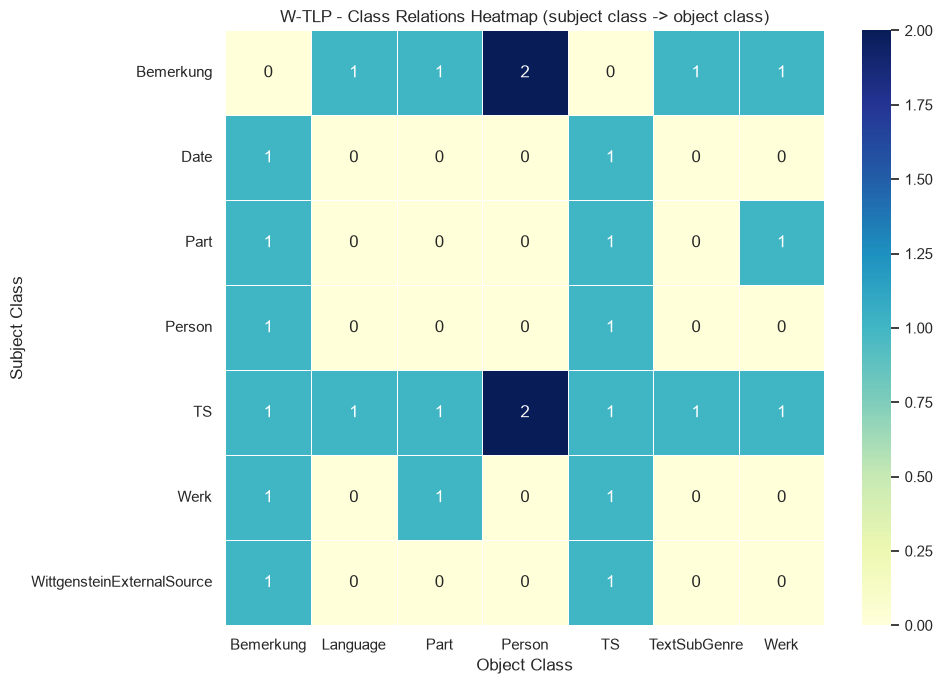

In [95]:
heatmap_data = (
    relations_df
    .groupby(["subject_class", "object_class"])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5
)
plt.title("W-TLP - Class Relations Heatmap (subject class -> object class)")
plt.xlabel("Object Class")
plt.ylabel("Subject Class")
plt.tight_layout()
plt.show()


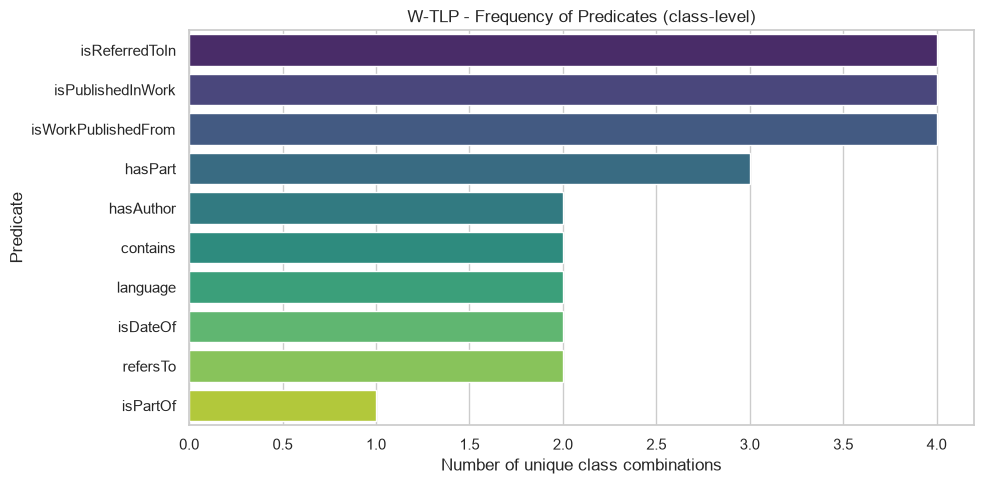

In [96]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=predicate_counts,
    x="count",
    y="predicate",
    hue="predicate",
    legend=False,
    palette="viridis"
)
plt.title("W-TLP - Frequency of Predicates (class-level)")
plt.xlabel("Number of unique class combinations")
plt.ylabel("Predicate")
plt.tight_layout()
plt.show()


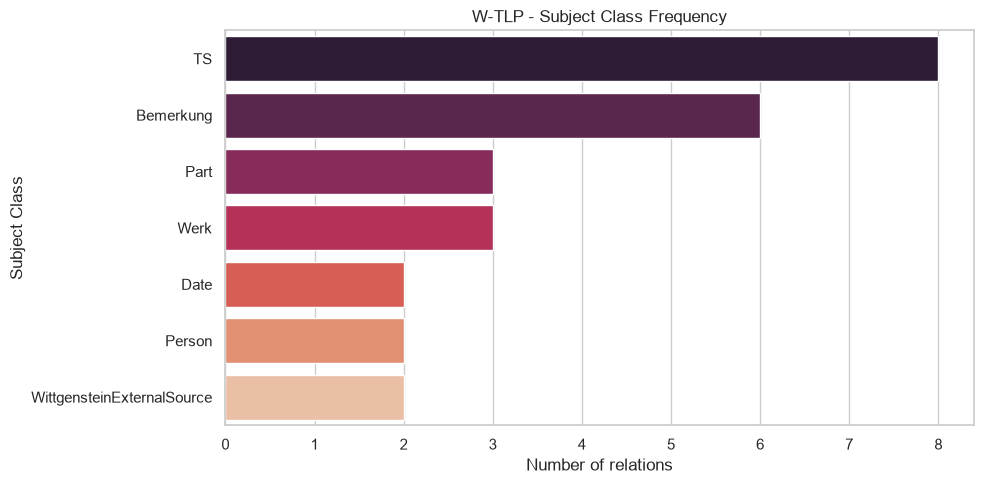

In [97]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=subject_counts,
    x="count",
    y="subject_class",
    hue="subject_class",
    legend=False,
    palette="rocket"
)
plt.title("W-TLP - Subject Class Frequency")
plt.xlabel("Number of relations")
plt.ylabel("Subject Class")
plt.tight_layout()
plt.show()


## 8. Resources in the neighborhood of W-TLP by class


In [101]:
related_resources = set()

for subject, predicate, obj in unique_triples:
    if isinstance(subject, URIRef):
        related_resources.add(subject)

    if isinstance(obj, URIRef):
        related_resources.add(obj)

print(f"Related resources: {len(related_resources):,}")

type_counter = Counter()
for res in related_resources:
    for t in get_resource_types(res):
        type_counter[get_local_name(t)] += 1

type_df = (
    pd.DataFrame.from_dict(type_counter, orient="index", columns=["count"])
    .sort_values("count", ascending=False)
    .reset_index()
    .rename(columns={"index": "class"})
)

display(type_df)


Related resources: 2,194


,class,count
0,TS,1619
1,Bemerkung,1616
2,Part,531
3,Person,21
4,WittgensteinExternalSource,13
5,TextSubGenre,6
6,Date,2
7,Werk,1
8,Language,1


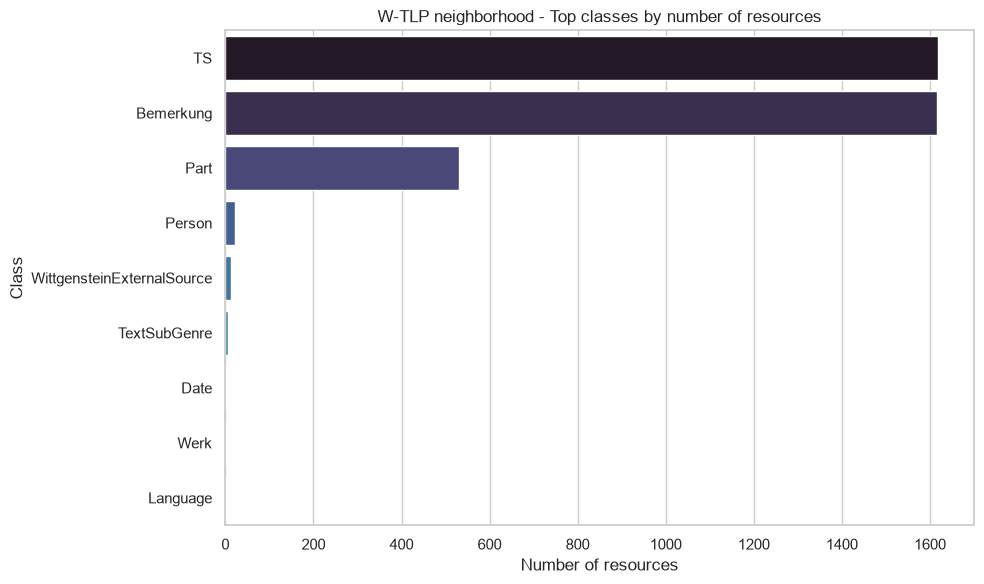

In [99]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=type_df.head(15),
    x="count",
    y="class",
    hue="class",
    legend=False,
    palette="mako"
)
plt.title("W-TLP neighborhood - Top classes by number of resources")
plt.xlabel("Number of resources")
plt.ylabel("Class")
plt.tight_layout()
plt.show()


## 9. Summary for alignment with PhiloSURFical

Key outputs for the next stage:

- `relations_df` — unique class-level relations around W-TLP
- `predicate_counts`, `subject_counts`, `object_counts`
- Neighborhood resource type distribution

These structures will be used for mapping to PhiloSURFical classes:
`Thesis`, `TextFragment`, `DefinedTerm`, `Book`, etc.


In [100]:
print("Ready for alignment.")
print(f"Class-level relations: {len(relations_df)}")
print(f"Neighborhood resources: {len(neighborhood):,}")


Ready for alignment.
Class-level relations: 26
Neighborhood resources: 2,194
